# NYC Restaurant Inspections Analysis

This project analyzes the **DOHMH New York City Restaurant Inspection Results** dataset from NYC Open Data. The notebook covers loading, exploring and cleaning the data before analysis.

## 1. Setup
Install the libraries used in this project: **pandas** for working with tables, **matplotlib** and **seaborn** for charts.

In [1]:
%pip install pandas matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


## 2. Load the data
The dataset was exported as a CSV from [NYC Open Data](https://data.cityofnewyork.us) and saved in the `data/` folder. It is read into a pandas DataFrame called `df`.

In [2]:
import pandas as pd

df = pd.read_csv("data/DOHMH_New_York_City_Restaurant_Inspection_Results_20261017.csv")
df.head()

,CAMIS,DBA,BORO,BUILDING,STREET,ZIPCODE,PHONE,CUISINE DESCRIPTION,INSPECTION DATE,ACTION,...,INSPECTION TYPE,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA,Location
0,50164639,WOOPS MACARONS,Manhattan,151,WEST 34 STREET,10001.0,9175876070,NaN,01/01/1900,NaN,...,NaN,40.750509,-73.989479,105.0,3.0,10900.0,1015219.0,1.008100e+09,MN17,POINT (-73.989479170444 40.750509164767)
1,50144587,SEA PARK,Manhattan,W 59TH ST,COLUMBUS CIRCLE,10023.0,9176265861,NaN,01/01/1900,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,50168738,Holiday Inn Express,Manhattan,538,WEST 48 STREET,10036.0,3474560149,NaN,01/01/1900,NaN,...,NaN,40.764189,-73.994545,104.0,3.0,12900.0,1090197.0,1.010760e+09,MN15,POINT (-73.994545368352 40.764189396983)
3,50180547,STICKY 1 LLC,Queens,81-27,LEFFERTS BOULEVARD,11415.0,9738005567,NaN,01/01/1900,NaN,...,NaN,40.708812,-73.830488,409.0,29.0,13600.0,4437659.0,4.033380e+09,QN60,POINT (-73.830488254666 40.708812139628)
4,50177942,SANTA CLAUS WORK SHOP / POFFERTJETS,Manhattan,59,COLUMBUS CIR,10023.0,2107021172,NaN,01/01/1900,NaN,...,NaN,40.768371,-73.982148,104.0,6.0,14500.0,NaN,1.000000e+00,MN14,POINT (-73.982147681103 40.768371147796)


## 3. Explore the data
Before changing anything, check the size of the dataset, its columns, missing values and the values in key columns.

**Size:** each row is one violation found during an inspection, not one restaurant, so one restaurant can appear many times.

In [3]:
df.shape

(296819, 27)

**Columns and data types:** the three date columns (`INSPECTION DATE`, `GRADE DATE`, `RECORD DATE`) are stored as text and need converting.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 296819 entries, 0 to 296818
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   CAMIS                  296819 non-null  int64  
 1   DBA                    296816 non-null  str    
 2   BORO                   296819 non-null  str    
 3   BUILDING               295814 non-null  str    
 4   STREET                 296767 non-null  str    
 5   ZIPCODE                293678 non-null  float64
 6   PHONE                  296711 non-null  str    
 7   CUISINE DESCRIPTION    292807 non-null  str    
 8   INSPECTION DATE        296819 non-null  str    
 9   ACTION                 292911 non-null  str    
 10  VIOLATION CODE         289895 non-null  str    
 11  VIOLATION DESCRIPTION  289895 non-null  str    
 12  CRITICAL FLAG          296819 non-null  str    
 13  SCORE                  279329 non-null  float64
 14  GRADE                  145253 non-null  str    

**Missing values per column:** `GRADE` and `GRADE DATE` are blank in over half the rows. This is expected, since not every inspection results in a letter grade. `SCORE` is missing in about 17,500 rows.

In [5]:
df.isna().sum().sort_values(ascending=False)

GRADE DATE               161843
GRADE                    151566
SCORE                     17490
VIOLATION CODE             6924
VIOLATION DESCRIPTION      6924
BIN                        5929
NTA                        4769
Community Board            4769
Location                   4769
Census Tract               4755
Council District           4755
CUISINE DESCRIPTION        4012
ACTION                     3908
INSPECTION TYPE            3908
ZIPCODE                    3141
BBL                        1691
Longitude                  1691
Latitude                   1691
BUILDING                   1005
PHONE                       108
STREET                       52
DBA                           3
INSPECTION DATE               0
RECORD DATE                   0
CRITICAL FLAG                 0
BORO                          0
CAMIS                         0
dtype: int64

**Most common cuisines:**

In [6]:
df["CUISINE DESCRIPTION"].value_counts().head(15)

CUISINE DESCRIPTION
American                          44060
Chinese                           29055
Coffee/Tea                        21382
Pizza                             17079
Latin American                    15399
Mexican                           12142
Bakery Products/Desserts          11777
Caribbean                         10981
Japanese                          10603
Italian                            9501
Chicken                            7893
Juice, Smoothies, Fruit Salads     5718
Asian/Asian Fusion                 5633
Spanish                            5569
Sandwiches                         5160
Name: count, dtype: int64

**Rows per borough:** 340 rows have a borough of `0`, which is not a valid value.

In [7]:
df["BORO"].value_counts()

BORO
Manhattan        109760
Brooklyn          75042
Queens            74524
Bronx             27601
Staten Island      9552
0                   340
Name: count, dtype: int64

**Grade values:** besides A, B and C, there are special codes:
- **N**: not yet graded
- **Z**: grade pending
- **P**: grade pending after a restaurant reopens

NYC scores inspections with violation points, so a **lower score is better**, and letter grades come from score ranges.

In [8]:
df["GRADE"].value_counts(dropna=False)

GRADE
NaN    151566
A       97963
B       17986
C       12995
N       10289
Z        5302
P         718
Name: count, dtype: int64

**Exact duplicate rows:**

In [9]:
df.duplicated().sum()

np.int64(204)

### Exploration findings
- 296,819 rows and 27 columns
- Date columns are stored as text
- About 3,900 placeholder rows dated **01/01/1900** belong to restaurants that have not been inspected yet
- 340 rows have an invalid borough (`0`)
- 204 rows are exact duplicates

## 4. Clean the data
Cleaning is done on a copy called `clean`, so the raw data in `df` is kept for reference.

In [10]:
# Work on a copy so the raw data in df stays untouched
clean = df.copy()

# 1. Drop exact duplicate rows
clean = clean.drop_duplicates()
clean.shape

(296615, 27)

In [11]:
# 2. Convert the date columns from text to real dates
for col in ["INSPECTION DATE", "GRADE DATE", "RECORD DATE"]:
    clean[col] = pd.to_datetime(clean[col], format="%m/%d/%Y")

clean[["INSPECTION DATE", "GRADE DATE", "RECORD DATE"]].dtypes

INSPECTION DATE    datetime64[us]
GRADE DATE         datetime64[us]
RECORD DATE        datetime64[us]
dtype: object

In [12]:
# 3. Remove placeholder rows for restaurants not yet inspected (dated 1/1/1900)
clean = clean[clean["INSPECTION DATE"] != "1900-01-01"]
clean["INSPECTION DATE"].min(), clean["INSPECTION DATE"].max()

(Timestamp('2007-08-10 00:00:00'), Timestamp('2026-10-15 00:00:00'))

In [13]:
# 4. Remove rows with an invalid borough ("0")
clean = clean[clean["BORO"] != "0"]
clean["BORO"].value_counts()

BORO
Manhattan        107969
Brooklyn          74014
Queens            73679
Bronx             27347
Staten Island      9426
Name: count, dtype: int64

In [14]:
# Size after cleaning
print("Before:", df.shape)
print("After: ", clean.shape)

Before: (296819, 27)
After:  (292435, 27)


### Cleaning summary
| Step | Result |
|---|---|
| Dropped exact duplicate rows | 204 rows removed |
| Converted date columns from text to dates | `INSPECTION DATE`, `GRADE DATE`, `RECORD DATE` |
| Removed placeholder rows dated 1/1/1900 | Inspection dates now range from 2007-08-10 to 2026-10-15 |
| Removed rows with invalid borough `0` | Only the five boroughs remain |

The dataset went from **296,819** to **292,435** rows.

**Kept on purpose:**
- Missing `GRADE` and `SCORE` values. Many inspections don't receive a grade, so these rows are still real data. How they are handled depends on how a "failing" inspection is defined in the next step.
- Older records going back to 2007. Most of the data is recent, so the analysis may focus on recent years.

## 5. One row per inspection
After cleaning, each row is still one **violation**, not one inspection. An inspection with 5 violations appears as 5 rows that all share the same `SCORE`. Counting rows would give extra weight to inspections with many violations, so the data is grouped into one row per inspection, identified by restaurant (`CAMIS`) plus `INSPECTION DATE`.

First, check which inspection types and critical-flag values exist:

In [15]:
clean["INSPECTION TYPE"].value_counts()

INSPECTION TYPE
Cycle Inspection / Initial Inspection                            157978
Cycle Inspection / Re-inspection                                  57018
Pre-permit (Operational) / Initial Inspection                     40578
Pre-permit (Operational) / Re-inspection                          10683
Administrative Miscellaneous / Initial Inspection                  9663
Pre-permit (Non-operational) / Initial Inspection                  3466
Cycle Inspection / Reopening Inspection                            2461
Cycle Inspection / Compliance Inspection                           1776
Pre-permit (Operational) / Compliance Inspection                   1773
Administrative Miscellaneous / Re-inspection                       1759
Inter-Agency Task Force / Initial Inspection                       1327
Pre-permit (Operational) / Reopening Inspection                     907
Smoke-Free Air Act / Initial Inspection                             654
Pre-permit (Non-operational) / Re-inspection    

In [16]:
clean["CRITICAL FLAG"].value_counts()

CRITICAL FLAG
Critical          155146
Not Critical      132453
Not Applicable      4836
Name: count, dtype: int64

Build the inspection-level table:
- `dropna(subset=["SCORE"])` removes rows with no score, since those inspections can't be judged
- `groupby([...])` bundles all violation rows from the same inspection
- `agg(...)` collapses each bundle into one row. Score, borough, cuisine and inspection type are the same across the bundle, so the first value is taken. A new column, `critical_violations`, counts the critical violations in each inspection.
- `reset_index()` turns the grouping keys back into normal columns

In [17]:
inspections = (
    clean.dropna(subset=["SCORE"])
    .groupby(["CAMIS", "INSPECTION DATE"])
    .agg(
        score=("SCORE", "first"),
        boro=("BORO", "first"),
        cuisine=("CUISINE DESCRIPTION", "first"),
        inspection_type=("INSPECTION TYPE", "first"),
        critical_violations=("CRITICAL FLAG", lambda s: (s == "Critical").sum()),
    )
    .reset_index()
)

inspections.shape

(82859, 7)

**Score distribution:** lower is better. NYC grades 0–13 points as an A, 14–27 as a B and 28+ as a C.

In [18]:
inspections["score"].describe()

count    82859.000000
mean        17.902678
std         14.932181
min          0.000000
25%          9.000000
50%         13.000000
75%         24.000000
max        214.000000
Name: score, dtype: float64

The median score (13) is below the mean (17.9), so scores are **right-skewed**: most inspections score low (good), while a minority score very high and pull the average up.

Grouping produced **82,859 inspections** from 292,435 violation rows, which is a more honest unit for comparing restaurants.

## 6. Define "failing" and keep initial inspections only
**Which inspections to keep:** re-inspections only happen after a bad result, so including them would inflate failure rates. Pre-permit inspections are for restaurants that haven't opened yet. Only **Cycle Inspection / Initial Inspection** is kept, since it is the routine check every open restaurant gets, which makes the comparison fair.

**What counts as failing:** two definitions are used.
- **Not an A (score 14 or higher):** the main definition. It matches the letter grade the public sees on the window, and since the median is 13, it splits inspections roughly in half.
- **C range (score 28 or higher):** a stricter, rarer outcome used as a **robustness check**. If the same cuisines and boroughs stand out under both definitions, the conclusions are more convincing.

`.copy()` makes `initial` a standalone table so later changes don't trigger warnings. Each comparison like `score >= 14` creates a True/False column. Pandas treats True as 1, so `.mean()` gives the **failure rate**.

In [19]:
initial = inspections[
    inspections["inspection_type"] == "Cycle Inspection / Initial Inspection"
].copy()

initial["not_A"] = initial["score"] >= 14
initial["fail_C"] = initial["score"] >= 28

initial.shape

(46830, 9)

In [20]:
initial[["not_A", "fail_C"]].mean()

not_A     0.399915
fail_C    0.180568
dtype: float64

Of the routine initial inspections, **46,830** remain. **40.0%** score worse than an A and **18.1%** land in the C range.

## 7. Who fails more often?
Failure rates are compared across boroughs, cuisines and years. Each table keeps an `inspections` count next to the rates, because a rate based on 300 inspections is much less reliable than one based on 15,000.

Keep in mind:
- **Check the counts first.** A high rate from few inspections is weak evidence.
- **Look at both definitions.** Groups that stand out on both `not_A_rate` and `fail_C_rate` are stronger findings.
- **These are associations, not causes.** Menu complexity, kitchen size or restaurant age could explain differences between groups.

### 7.1 Boroughs
`groupby("boro")` splits the inspections into five groups. For each group, `agg` counts the inspections (`size`) and takes the mean of the True/False columns, which gives each borough's failure rate.

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

by_boro = (
    initial.groupby("boro")
    .agg(
        inspections=("not_A", "size"),
        not_A_rate=("not_A", "mean"),
        fail_C_rate=("fail_C", "mean"),
    )
    .sort_values("not_A_rate", ascending=False)
)
by_boro

,inspections,not_A_rate,fail_C_rate
boro,,,
Staten Island,1711,0.445938,0.142607
Queens,10841,0.428650,0.215109
Bronx,4474,0.418865,0.167412
Brooklyn,12069,0.389013,0.181125
Manhattan,17735,0.380547,0.166056


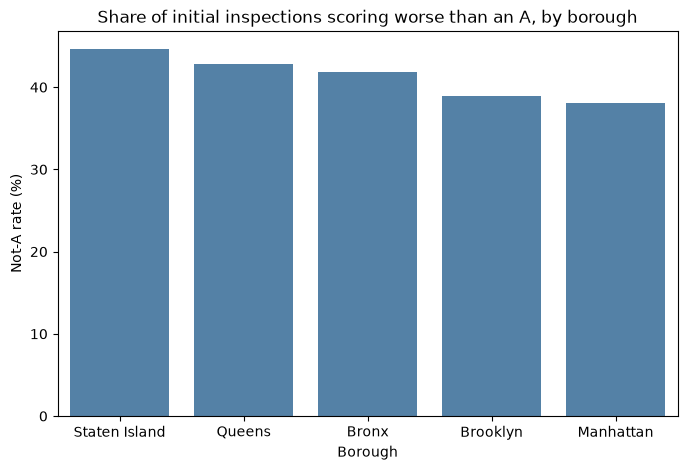

In [22]:
plot_data = by_boro.reset_index()
plot_data["not_A_pct"] = plot_data["not_A_rate"] * 100

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_data, x="boro", y="not_A_pct", color="steelblue")
plt.title("Share of initial inspections scoring worse than an A, by borough")
plt.xlabel("Borough")
plt.ylabel("Not-A rate (%)")
plt.show()

### 7.2 Cuisines
There are dozens of cuisines, and some have only a handful of inspections. `.query("inspections >= 200")` keeps only cuisines with at least 200 inspections. **The 200 cutoff is a judgment call** made to avoid unreliable rates from small groups.

In [23]:
by_cuisine = (
    initial.groupby("cuisine")
    .agg(
        inspections=("not_A", "size"),
        not_A_rate=("not_A", "mean"),
        fail_C_rate=("fail_C", "mean"),
    )
    .query("inspections >= 200")
    .sort_values("not_A_rate", ascending=False)
)

print(by_cuisine.head(10))
print(by_cuisine.tail(10))

                    inspections  not_A_rate  fail_C_rate
cuisine                                                 
Indian                      455    0.632967     0.327473
Thai                        525    0.598095     0.312381
Asian/Asian Fusion          616    0.584416     0.300325
Caribbean                  1428    0.551120     0.291317
Spanish                     727    0.536451     0.257221
Latin American             1993    0.521826     0.269945
Chinese                    3604    0.515261     0.256937
Greek                       237    0.506329     0.265823
Korean                      587    0.487223     0.243612
Jewish/Kosher               562    0.460854     0.256228
                                inspections  not_A_rate  fail_C_rate
cuisine                                                             
Sandwiches/Salads/Mixed Buffet          292    0.352740     0.133562
American                               8483    0.342096     0.145821
Sandwiches                              

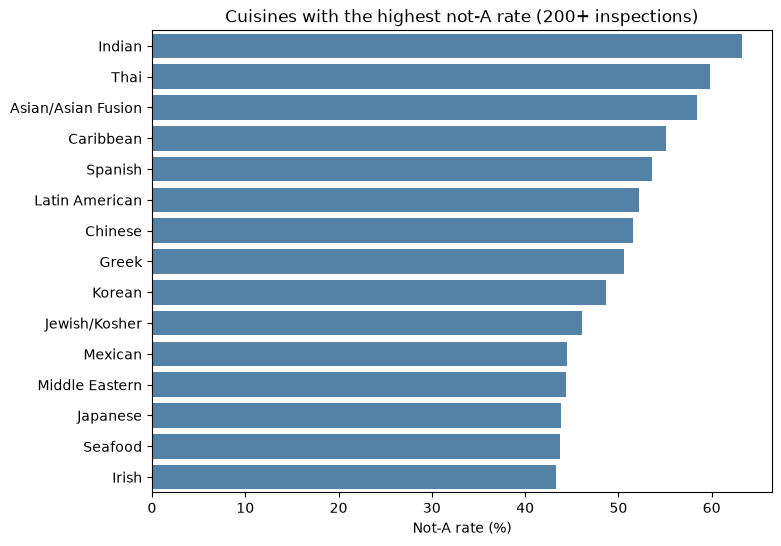

In [24]:
top15 = by_cuisine.head(15).reset_index()
top15["not_A_pct"] = top15["not_A_rate"] * 100

plt.figure(figsize=(8, 6))
sns.barplot(data=top15, y="cuisine", x="not_A_pct", color="steelblue")
plt.title("Cuisines with the highest not-A rate (200+ inspections)")
plt.xlabel("Not-A rate (%)")
plt.ylabel("")
plt.savefig("cuisine_chart.png", dpi=200, bbox_inches="tight")
plt.show()

### 7.3 Time
`.dt.year` pulls the year out of the inspection date, which works because the dates were converted earlier. Early years may have very few inspections, and **2026 is only a partial year**, so check the `inspections` column before trusting any year.

In [25]:
initial["year"] = initial["INSPECTION DATE"].dt.year

by_year = (
    initial.groupby("year")
    .agg(
        inspections=("not_A", "size"),
        not_A_rate=("not_A", "mean"),
        fail_C_rate=("fail_C", "mean"),
    )
)
by_year

,inspections,not_A_rate,fail_C_rate
year,,,
2007,3,1.000000,0.666667
2009,1,1.000000,1.000000
2010,2,1.000000,0.500000
2011,1,1.000000,0.000000
2012,1,1.000000,0.000000
2014,2,0.500000,0.000000
2015,4,0.500000,0.000000
2016,50,0.280000,0.080000
2017,110,0.200000,0.072727


Only years with 500+ inspections are plotted. `* [1, 100, 100]` multiplies the count column by 1 and the two rates by 100, so the rates read as percentages. `ax.set_xticks(yearly.index)` puts tick marks only at the actual years, so the axis doesn't show decimals like 2022.5.

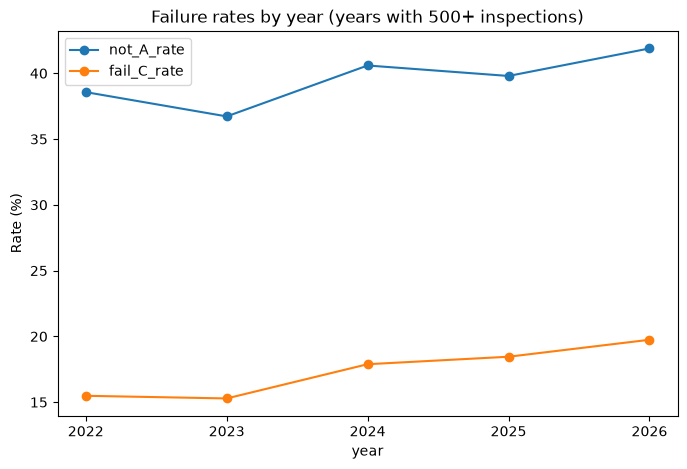

In [26]:
yearly = by_year.query("inspections >= 500") * [1, 100, 100]

ax = yearly[["not_A_rate", "fail_C_rate"]].plot(marker="o", figsize=(8, 5))
ax.set_xticks(yearly.index)
plt.title("Failure rates by year (years with 500+ inspections)")
plt.ylabel("Rate (%)")
plt.show()

### 7.4 Is the cuisine effect just a borough effect?
A skeptical reader might ask whether some cuisines fail more simply because more of them are in higher-failing boroughs, such as Queens. To test this, the not-A rate is computed for each cuisine **within each borough**, keeping only combinations with 100+ inspections. If Indian and Thai stay high in every borough, the cuisine effect is not a side effect of location.

In [27]:
top_cuisines = ["Indian", "Thai", "Chinese", "American", "Coffee/Tea"]

check = (
    initial[initial["cuisine"].isin(top_cuisines)]
    .groupby(["cuisine", "boro"])["not_A"]
    .agg(["size", "mean"])
    .query("size >= 100")
    .round(3)
)
check

size   mean
cuisine    boro                      
American   Bronx           559  0.365
           Brooklyn       1828  0.338
           Manhattan      4274  0.337
           Queens         1527  0.336
           Staten Island   295  0.427
Chinese    Bronx           425  0.464
           Brooklyn       1102  0.442
           Manhattan       811  0.586
           Queens         1127  0.545
           Staten Island   139  0.604
Coffee/Tea Bronx           175  0.286
           Brooklyn       1166  0.280
           Manhattan      2092  0.270
           Queens          572  0.287
Indian     Manhattan       206  0.578
           Queens          135  0.667
Thai       Brooklyn        159  0.553
           Manhattan       226  0.642
           Queens          124  0.597

## Conclusions

**Question:** What factors are associated with NYC restaurants scoring worse than an A on routine health inspections?

**Findings**
- Cuisine shows a much larger gap than borough. Not-A rates range from about 18% (Donuts) to 63% (Indian) across cuisines with 200+ inspections, while boroughs differ by only about 6 points (38% to 45%).
- The cuisine gap holds within boroughs. In Manhattan, for example, Thai restaurants score worse than an A 64% of the time and Coffee/Tea shops 27%.
- Indian, Thai, and Asian/Asian Fusion restaurants are highest under both definitions of failing (not-A and C-range).
- Failure rates rose modestly from 2022 to 2026 (2026 is a partial year).

**Limitations**
- These are associations, not causes. Menu complexity, kitchen size, restaurant age, and chain status could all play a role and are not controlled for.
- Only routine initial inspections are included. Re-inspections and pre-permit inspections are excluded.
- Before 2022 there are too few initial inspections to analyze.
- Indian restaurants have enough data in only two boroughs, and Staten Island has the smallest sample, so its results are the least reliable.
- "Failing" is my definition (score of 14 or higher, with 28 or higher as a stricter check), not an official category.